# 02. Customer Segmentation with RFM Features and K-Means

Goal: build RFM style features and cluster customers with K-Means, choosing k with the Elbow method and the silhouette score.

RFM proxies. The dataset has no transaction log, so proxies are used:

* Recency is represented by tenure, the number of months as a customer
* Frequency is represented by the number of subscribed services
* Monetary is represented by MonthlyCharges

Outputs:

* ../data/processed/telco_segmented.csv
* ../results/figures/elbow_silhouette.png
* ../results/tables/segment_profiles.csv


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

SEED = 42
np.random.seed(SEED)
sns.set_style('whitegrid')
NAVY, BLUE, TEAL, CORAL = '#0A2540', '#1C7293', '#00A896', '#F4845F'

df = pd.read_csv('../data/processed/telco_clean.csv')
print(f'Loaded: {df.shape}')

Loaded: (7032, 23)


## 1. Build RFM style features

In [18]:
service_cols = ['PhoneService','MultipleLines','InternetService','OnlineSecurity',
                'OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

def count_services(row):
    # Count only services the customer actually subscribes to
    return sum(1 for c in service_cols
               if row[c] not in ['No', 'No phone service', 'No internet service'])

df['NumServices'] = df.apply(count_services, axis=1)

# Assemble the RFM matrix
rfm = df[['tenure', 'NumServices', 'MonthlyCharges']].copy()
rfm.columns = ['Recency', 'Frequency', 'Monetary']
print(rfm.describe().round(2))

       Recency  Frequency  Monetary
count  7032.00    7032.00   7032.00
mean     32.42       4.15     64.80
std      24.55       2.31     30.09
min       1.00       1.00     18.25
25%       9.00       2.00     35.59
50%      29.00       4.00     70.35
75%      55.00       6.00     89.86
max      72.00       9.00    118.75


## 2. Scale the features

K-Means uses Euclidean distance, so features on different scales must be standardised to mean 0 and standard deviation 1. Otherwise MonthlyCharges would dominate NumServices.

In [19]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)
print('Scaled shape:', rfm_scaled.shape)

Scaled shape: (7032, 3)


## 3. Choose k with the Elbow method and silhouette score

We test k from 2 to 6. The Elbow method looks at how the within cluster sum of squares decreases as k increases, and we look for the point where the improvement flattens. The silhouette score measures how well separated and cohesive the clusters are.

Note that the silhouette scores for small values of k are often close to each other, so the final choice should also consider whether the resulting segments make business sense.

In [20]:
ks = range(2, 7)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(rfm_scaled, labels))

for k, i, s in zip(ks, inertias, silhouettes):
    print(f'k={k}  inertia={i:>9.1f}  silhouette={s:.4f}')

k=2  inertia=  10494.8  silhouette=0.4217
k=3  inertia=   6652.5  silhouette=0.4200
k=4  inertia=   4949.2  silhouette=0.4266
k=5  inertia=   4031.3  silhouette=0.3849
k=6  inertia=   3202.2  silhouette=0.4011


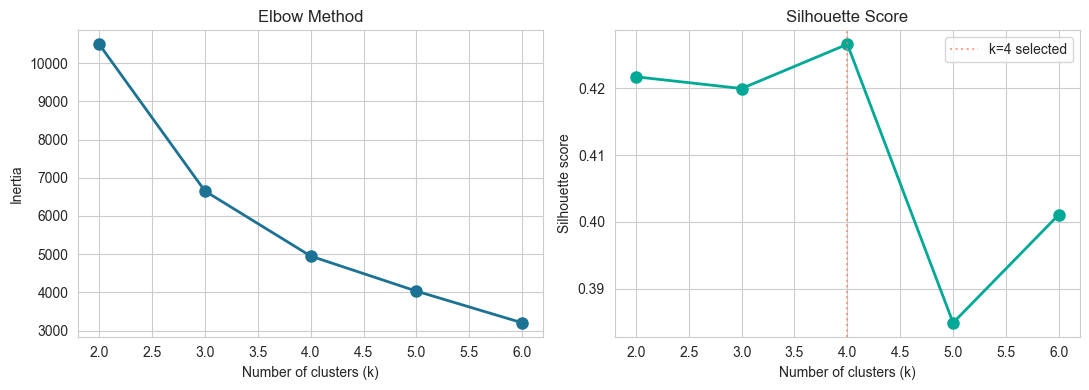

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(list(ks), inertias, 'o-', color=BLUE, linewidth=2, markersize=8)
ax1.set_xlabel('Number of clusters (k)'); ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(list(ks), silhouettes, 'o-', color=TEAL, linewidth=2, markersize=8)
ax2.axvline(4, color=CORAL, linestyle=':', alpha=0.7, label='k=4 selected')
ax2.set_xlabel('Number of clusters (k)'); ax2.set_ylabel('Silhouette score')
ax2.set_title('Silhouette Score'); ax2.legend()

plt.tight_layout()
plt.savefig('../results/figures/elbow_silhouette.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Fit the final K-Means model with k equal to 4

k=4 gives the highest silhouette score, around 0.43, and produces four segments that can be described in business terms.

In [22]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10)
df['Segment'] = kmeans.fit_predict(rfm_scaled)

profile = df.groupby('Segment').agg(
    Customers=('customerID', 'count'),
    AvgTenure=('tenure', 'mean'),
    AvgServices=('NumServices', 'mean'),
    AvgMonthly=('MonthlyCharges', 'mean'),
    ChurnRate=('ChurnBinary', 'mean')
).round(2)
profile['ChurnRate'] = (profile['ChurnRate']*100).round(1)
print(profile)

         Customers  AvgTenure  AvgServices  AvgMonthly  ChurnRate
Segment                                                          
0             2156      57.39         6.72       91.30       16.0
1             1498      10.28         1.65       29.17       24.0
2             2406      14.93         4.24       77.24       47.0
3              972      54.47         2.06       30.13        4.0


## 5. Interpret and name the segments

Give each numeric cluster a readable label based on its profile. Cluster numbers can differ between runs on different machines, so always name segments by their characteristics rather than by their number.

In [23]:
# Assign names automatically from each segment's profile,
# so the labels stay correct even if cluster numbers change.
segment_names = {}
for seg in profile.index:
    tenure   = profile.loc[seg, 'AvgTenure']
    services = profile.loc[seg, 'AvgServices']
    monthly  = profile.loc[seg, 'AvgMonthly']

    if tenure > 40 and services > 4:
        segment_names[seg] = 'Premium Loyal'
    elif tenure > 40:
        segment_names[seg] = 'Long-term Minimal'
    elif monthly > 60:
        segment_names[seg] = 'At-Risk High-Spend'
    else:
        segment_names[seg] = 'New Low-Spend'

df['SegmentName'] = df['Segment'].map(segment_names)

print('Assigned names:')
for seg, name in sorted(segment_names.items()):
    print(f'  Segment {seg} -> {name}')
print()
print(df.groupby('SegmentName')['ChurnBinary'].agg(['count', 'mean']).round(3))

Assigned names:
  Segment 0 -> Premium Loyal
  Segment 1 -> New Low-Spend
  Segment 2 -> At-Risk High-Spend
  Segment 3 -> Long-term Minimal

                    count   mean
SegmentName                     
At-Risk High-Spend   2406  0.470
Long-term Minimal     972  0.041
New Low-Spend        1498  0.240
Premium Loyal        2156  0.156


## 6. Save

In [24]:
profile.to_csv('../results/tables/segment_profiles.csv')
df.to_csv('../data/processed/telco_segmented.csv', index=False)
print('Saved: segment_profiles.csv, telco_segmented.csv, elbow_silhouette.png')

Saved: segment_profiles.csv, telco_segmented.csv, elbow_silhouette.png
